In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("marathon.csv")
df

,Rank,Time,Name,Country,Date of Birth,Place,City,Date,Gender,Event
0,1,1:59:30,Sabastian Kimaru Sawe,KEN,16.03.1995,1,London,26.04.2026,Men,Marathon
1,1,2:09:56,Ruth Chepngetich,KEN,08.08.1994,1,Chicago,13.10.2024,Women,Marathon
2,2,2:10:51,Fotyen Tesfay,ETH,17.02.1998,1,Barcelona,15.03.2026,Women,Marathon
3,2,1:59:41,Yomif Kejelcha,ETH,01.08.1997,2,London,26.04.2026,Men,Marathon
4,3,2:00:28,Jacob Kiplimo,UGA,14.11.2000,3,London,26.04.2026,Men,Marathon
...,...,...,...,...,...,...,...,...,...,...
16998,10993,2:12:00,Benjamin Malaty,FRA,07.05.1986,13,Paris,07.04.2013,Men,Marathon
16999,10993,2:12:00,Arkadiusz Sowa,POL,02.03.1979,7,Berlin,30.09.2007,Men,Marathon
17000,10993,2:12:00,Tekeste Nekatibebe,ETH,14.02.1988,3,Enschede,27.04.2008,Men,Marathon
17001,10993,2:12:00,Tesfaye Dereje,ETH,30.09.1985,4,Enschede,27.04.2008,Men,Marathon


In [2]:
df.head()

,Rank,Time,Name,Country,Date of Birth,Place,City,Date,Gender,Event
0,1,1:59:30,Sabastian Kimaru Sawe,KEN,16.03.1995,1,London,26.04.2026,Men,Marathon
1,1,2:09:56,Ruth Chepngetich,KEN,08.08.1994,1,Chicago,13.10.2024,Women,Marathon
2,2,2:10:51,Fotyen Tesfay,ETH,17.02.1998,1,Barcelona,15.03.2026,Women,Marathon
3,2,1:59:41,Yomif Kejelcha,ETH,01.08.1997,2,London,26.04.2026,Men,Marathon
4,3,2:00:28,Jacob Kiplimo,UGA,14.11.2000,3,London,26.04.2026,Men,Marathon


In [3]:
df.shape

(17003, 10)

In [4]:
df.describe()

,Rank
count,17003.000000
mean,4620.046227
std,3013.023471
min,1.000000
25%,2119.000000
50%,4235.000000
75%,6781.000000
max,10993.000000


In [5]:
df.dtypes

Rank             int64
Time               str
Name               str
Country            str
Date of Birth      str
Place              str
City               str
Date               str
Gender             str
Event              str
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17003 entries, 0 to 17002
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Rank           17003 non-null  int64
 1   Time           17003 non-null  str  
 2   Name           17003 non-null  str  
 3   Country        17003 non-null  str  
 4   Date of Birth  16819 non-null  str  
 5   Place          16999 non-null  str  
 6   City           17003 non-null  str  
 7   Date           17003 non-null  str  
 8   Gender         17003 non-null  str  
 9   Event          17003 non-null  str  
dtypes: int64(1), str(9)
memory usage: 1.3 MB


In [7]:
df.isna().sum()

Rank               0
Time               0
Name               0
Country            0
Date of Birth    184
Place              4
City               0
Date               0
Gender             0
Event              0
dtype: int64

Create a new column named Time_seconds to calculate marathon times into seconds, so its easier to compare and analyze

In [8]:
df["Time_seconds"] = pd.to_timedelta(
    df["Time"], errors="coerce"
).dt.total_seconds()

I see there are 184 rows with NaN values in DOB and 4 rows with Place as NaN. I will drop all of them since I am evaluating on such columns and I can't get an "avg" value for them, and I have sufficient rows so removing 188 rows wouldn't hurt the analysis and cause bias.

In [9]:
df_cleaned = df.dropna()
df_cleaned

,Rank,Time,Name,Country,Date of Birth,Place,City,Date,Gender,Event,Time_seconds
0,1,1:59:30,Sabastian Kimaru Sawe,KEN,16.03.1995,1,London,26.04.2026,Men,Marathon,7170.0
1,1,2:09:56,Ruth Chepngetich,KEN,08.08.1994,1,Chicago,13.10.2024,Women,Marathon,7796.0
2,2,2:10:51,Fotyen Tesfay,ETH,17.02.1998,1,Barcelona,15.03.2026,Women,Marathon,7851.0
3,2,1:59:41,Yomif Kejelcha,ETH,01.08.1997,2,London,26.04.2026,Men,Marathon,7181.0
4,3,2:00:28,Jacob Kiplimo,UGA,14.11.2000,3,London,26.04.2026,Men,Marathon,7228.0
...,...,...,...,...,...,...,...,...,...,...,...
16998,10993,2:12:00,Benjamin Malaty,FRA,07.05.1986,13,Paris,07.04.2013,Men,Marathon,7920.0
16999,10993,2:12:00,Arkadiusz Sowa,POL,02.03.1979,7,Berlin,30.09.2007,Men,Marathon,7920.0
17000,10993,2:12:00,Tekeste Nekatibebe,ETH,14.02.1988,3,Enschede,27.04.2008,Men,Marathon,7920.0
17001,10993,2:12:00,Tesfaye Dereje,ETH,30.09.1985,4,Enschede,27.04.2008,Men,Marathon,7920.0


I will change the str type of 'Date of Birth' and 'Date' into datetime type.
Then, I will create an 'Age' column using Date of Birth, and sort by Age at the time of the race (from youngest to oldest)

In [10]:
df_cleaned["Date of Birth"] = pd.to_datetime(df_cleaned["Date of Birth"], dayfirst=True)
df_cleaned["Date"] = pd.to_datetime(df_cleaned["Date"], dayfirst=True)
df_cleaned["Age"] = (
    (df_cleaned["Date"] - df_cleaned["Date of Birth"]).dt.days / 365.2425
)
df_sorted_by_age = df_cleaned.sort_values(by="Age")
df_sorted_by_age

,Rank,Time,Name,Country,Date of Birth,Place,City,Date,Gender,Event,Time_seconds,Age
13343,7376,2:10:47,Jonathan Cherono,KEN,1987-05-06,8,Beijing,2001-10-14,Men,Marathon,7847.0,14.442459
6937,3458,2:27:37,Cui Lu,CHN,1987-03-29,9,Beijing,2002-10-13,Women,Marathon,8857.0,15.543098
11125,5553,2:29:41,Meiyu Shen,CHN,1987-03-21,10,Beijing,2002-10-13,Women,Marathon,8981.0,15.565001
6732,3351,2:27:30,Dongmei Ai,CHN,1981-10-15,3,Beijing,1997-10-04,Women,Marathon,8850.0,15.970212
10235,5114,2:29:17,Muluhabt Tsega,ETH,1997-12-22,1,Beirut,2014-11-09,Women,Marathon,8957.0,16.881935
...,...,...,...,...,...,...,...,...,...,...,...,...
7860,3914,2:09:10,Mark Kosgei Kiptoo,KEN,1976-06-21,12,Seoul,2024-03-17,Men,Marathon,7750.0,47.738147
13672,7700,2:10:54,Mark Kosgei Kiptoo,KEN,1976-06-21,1,Casino - Stadion,2024-10-13,Men,Marathon,7854.0,48.313107
14651,8693,2:11:16,Mark Kosgei Kiptoo,KEN,1976-06-21,7,Mersin,2024-12-15,Men,Marathon,7876.0,48.485595
8180,4080,2:09:16,Mark Kosgei Kiptoo,KEN,1976-06-21,1,Zürich,2025-04-13,Men,Marathon,7756.0,48.811406


In [11]:
correlation = df_sorted_by_age["Age"].corr(
    df_sorted_by_age["Time_seconds"]
)

print("Correlation:", round(correlation, 3))

Correlation: 0.022


Because the correlation between age and time is closer to 0 than it is to 1, there is little linear relationship between age and finish times.

I will create a boxplot to display median finish times by age groups.

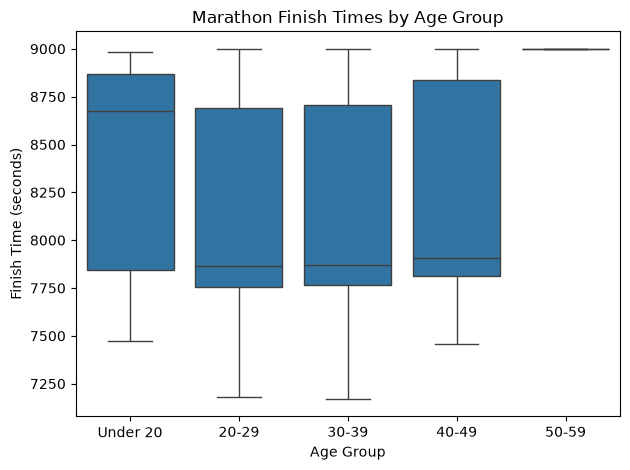

In [12]:
df_sorted_by_age["Age_Group"] = pd.cut(
    df_sorted_by_age["Age"],
    bins=[0, 19, 29, 39, 49, 59],
    labels=["Under 20", "20-29", "30-39", "40-49", "50-59"]
)

sns.boxplot(data=df_sorted_by_age, x="Age_Group", y="Time_seconds")

plt.title("Marathon Finish Times by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Finish Time (seconds)")
plt.tight_layout()
plt.show()

Based on the boxplot and the correlation, there isn't much relation between age and marathon time.

In [13]:
country_counts = df_cleaned["Country"].value_counts()
country_counts

Country
KEN    5314
ETH    3967
JPN    1881
USA     517
CHN     392
       ... 
AZE       1
VEN       1
ANG       1
SUD       1
GEO       1
Name: count, Length: 93, dtype: int64

Since there are too many countries, I will only compare the top 15 countries with the most runners.

In [14]:
df_cleaned["Place"] = pd.to_numeric(df_cleaned["Place"], errors="coerce")

df_first_place = df_cleaned[df_cleaned["Place"] == 1]

top_15_winners = (
    df_first_place["Country"]
    .value_counts()
    .head(15)
)

print("Top 15 countries by first-place finishes:")
print(top_15_winners)

Top 15 countries by first-place finishes:
Country
KEN    1326
ETH     868
JPN     196
USA      86
RUS      86
CHN      77
MAR      61
ITA      55
GER      50
GBR      49
RSA      44
BRN      41
AUS      37
ESP      36
POL      35
Name: count, dtype: int64


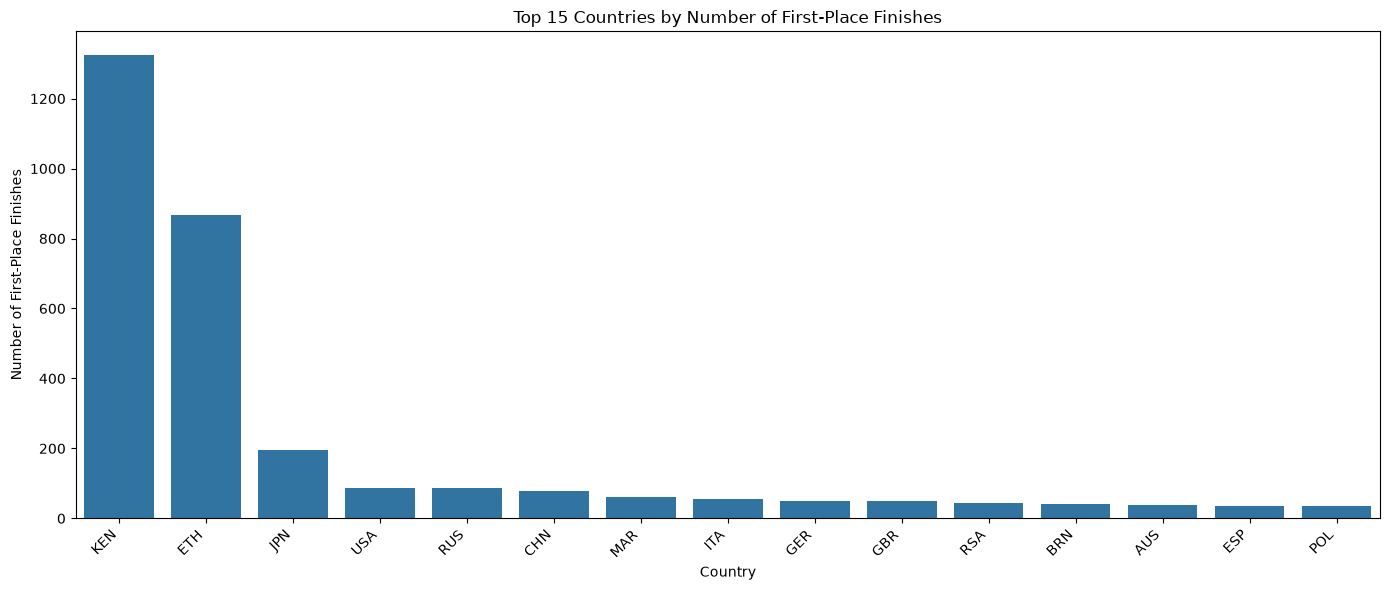

In [15]:
plt.figure(figsize=(14, 6))

sns.barplot(
    x=top_15_winners.index,
    y=top_15_winners.values,
)

plt.title("Top 15 Countries by Number of First-Place Finishes")
plt.xlabel("Country")
plt.ylabel("Number of First-Place Finishes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Based on the bar graph, Kenya and Ethiopia definitely have a high number of first-place finishes and both of their sample size is huge as well (5314 and 3967 respectively). Although it is incorrect to say that all marathon runners from Kenya and Ethiopia finish first place, it is very likely that runners from those two countries will win the race.

In [16]:
top_cities = df_cleaned["City"].value_counts().head(10).index

df_city_top10 = df_cleaned[df_cleaned["City"].isin(top_cities)]

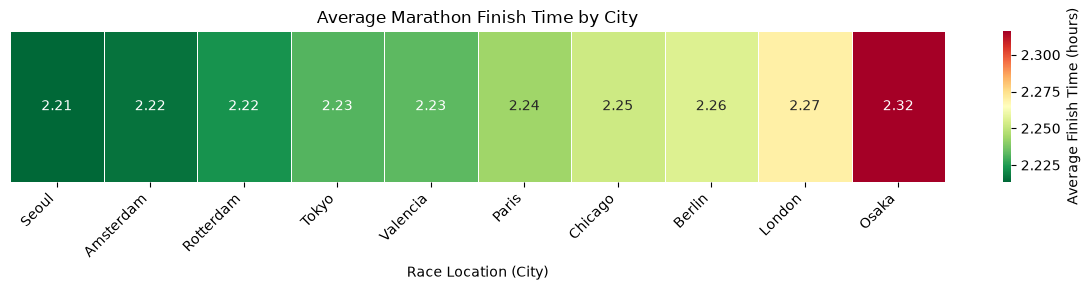

In [17]:
city_avg = (
    df_city_top10.groupby("City")["Time_seconds"]
    .mean()
    .sort_values()
)

city_avg_hours = city_avg / 3600

plt.figure(figsize=(12, 3))
sns.heatmap(
    city_avg_hours.to_frame().T,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    linewidths=0.5,
    cbar_kws={"label": "Average Finish Time (hours)"}
)

plt.title("Average Marathon Finish Time by City")
plt.xlabel("Race Location (City)")
plt.ylabel("")
plt.yticks([])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Used AI in creating the heatmap.
Prompt Log:
I have built [code I have so far] for my project.
I am now working on how race location (City) has influence on marathon performance.
Create a heatmap for it and compute mean and median values for the top 10 cities with the most runners.

In [18]:
city_performance = (
    df_city_top10.groupby("City")["Time_seconds"]
    .agg(["count", "mean", "median"])
    .sort_values("median")
)

print(city_performance)

           count         mean  median
City                                 
Amsterdam    426  7978.265258  7768.5
Seoul        462  7969.049784  7798.5
Rotterdam    474  8002.710970  7817.5
Valencia     544  8038.891544  7829.5
Paris        522  8076.775862  7845.0
Tokyo        723  8035.211618  7847.0
Berlin       649  8120.228043  7868.0
Chicago      530  8107.394340  7870.5
London       793  8171.645649  7903.0
Osaka        494  8337.386640  8587.5


Based on the heatmap, mean and median values for the top 10 cities with the most runners, it is likely that runners would perform better at Seoul Marathon than they would at Osaka Marathon.

Repo Address: https://github.com/yeonghwang-hub/cs82a-portfolio